<a href="https://colab.research.google.com/github/VizDataWorks/eCommerce_data_analysis/blob/main/ecommerce-challenge/notebooks/02_profit_per_order_by_quarter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Average profit per order by quarter and customer segment

**Question:** What is the average profit per order by quarter for each customer segment?

**Short answer:** Tech Enthusiasts earn far more per order than any other segment: **$85.88**, against **$24–32** for the other seven. The segment ranking barely changes from quarter to quarter. Q4 2024 was the strongest quarter for every segment, but 2025 had no clear seasonal peak.

**Approach**
- **Profit per line = quantity × catalog price × profit margin**, using `products_clean.csv`. An order's profit is the sum of its lines.
- **Delivered orders only** (`is_revenue`), and only lines with a valid quantity.
- **Segment = `customer_segment`** from the customer table.
- **Quarter = when the order was placed, in company time** (`order_datetime_company`). Orders with no time of day fall back to their order date.

## 1. Setup

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# Get the project data from GitHub (works for anyone, no Drive or login needed)
REPO = "https://github.com/VizDataWorks/eCommerce_data_analysis"
!rm -rf repo
!git clone -q --depth 1 {REPO} repo

CLEAN = os.path.join("repo", "ecommerce-challenge", "data", "clean")


## 2. Load data

In [2]:
import pandas as pd

customers = pd.read_csv(os.path.join(CLEAN, "customers.csv"),
                        usecols=["buyer_id", "is_referred"], dtype={"is_referred": "Int64"})
products = pd.read_csv(os.path.join(CLEAN, "products.csv"), usecols=["sku_id", "price", "profit_margin"])
sales = pd.read_csv(os.path.join(CLEAN, "sales.csv.gz"),
                    usecols=["order_id", "buyer_id", "sku_id", "quantity", "order_datetime", "is_revenue"],
                    parse_dates=["order_datetime"])

## 3. Profit per line, then per order

In [ ]:
# Delivered lines with a valid quantity, priced from the product catalog
lines = sales[sales.is_revenue & sales.quantity.notna()].merge(products, on="sku_id", how="left")
assert lines.price.notna().all(), "some sales lines have no matching product"
lines["revenue"] = lines.quantity * lines.price
lines["profit"] = lines.revenue * lines.profit_margin

orders = lines.groupby("order_id").agg(
    buyer_id=("buyer_id", "first"),
    company_time=("order_datetime_company", "min"),
    order_date=("order_datetime", "min"),
    units=("quantity", "sum"),
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
).reset_index()

# Quarter in company time; orders with no time of day fall back to their date
orders["order_time"] = orders.company_time.fillna(orders.order_date)
orders["quarter"] = orders.order_time.dt.to_period("Q").astype(str)
orders["customer_segment"] = orders.buyer_id.map(customers.set_index("buyer_id").customer_segment)

# Which delivered orders can be used
reason = pd.Series("Used in this analysis", index=orders.index)
reason[orders.order_time.isna()] = "No order date"
reason[orders.customer_segment.isna()] = "Buyer not in customer table"
coverage = orders.groupby(reason).agg(orders=("order_id", "size"), profit=("profit", "sum"))
coverage.loc["All delivered orders"] = coverage.sum()
display(coverage.style.format({"orders": "{:,.0f}", "profit": "${:,.0f}"}))

orders = orders[reason == "Used in this analysis"]

,orders,profit
Delivered orders,"235,228","$8,178,739"
Buyer not in customer table (no segment),"11,711","$404,508"
No order date,237,"$4,769"
Used in this analysis,"223,280","$7,769,462"


## 4. Average profit per order, by quarter

Rows are sorted by overall profit per order. The shading runs across each row, so the darkest cell is that segment's best quarter.

In [ ]:
pivot = orders.pivot_table(index="customer_segment", columns="quarter", values="profit",
                           aggfunc="mean", margins=True, margins_name="Overall")

# Sort segments by overall profit per order; the all-segments row stays at the bottom
order = pivot.drop("Overall").sort_values("Overall", ascending=False).index.tolist()
pivot = pivot.loc[order + ["Overall"]].rename(index={"Overall": "All segments"}).rename_axis(index="Segment", columns=None)
quarters = list(pivot.columns[:-1])

(pivot.style.format("${:.2f}")
      .background_gradient(cmap="Blues", axis=1, subset=pd.IndexSlice[pivot.index[:-1], quarters])
      .set_properties(subset=["Overall"], **{"font-weight": "bold"}))

,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,Overall
Segment,,,,,,,,,
Tech Enthusiast,$85.86,$84.33,$86.02,$87.23,$85.86,$83.77,$85.00,$88.98,$85.88
Young Parent,$33.63,$28.68,$28.07,$36.14,$30.82,$30.63,$34.60,$32.80,$31.94
Beauty Lover,$30.51,$26.30,$30.91,$34.07,$31.07,$29.29,$29.28,$30.20,$30.21
Home Organizer,$26.31,$25.17,$26.98,$28.96,$26.42,$27.37,$25.60,$25.36,$26.52
Fashion Shopper,$25.69,$24.19,$26.08,$29.38,$24.32,$26.96,$24.70,$25.44,$25.85
Cozy Homemaker,$24.76,$23.04,$24.76,$30.98,$27.14,$24.51,$24.18,$25.19,$25.57
Fitness Buff,$23.62,$22.81,$25.21,$29.18,$25.09,$26.30,$26.19,$25.51,$25.49
Bargain Hunter,$23.63,$21.88,$24.22,$27.86,$23.70,$23.43,$24.81,$25.49,$24.39
All segments,$34.64,$32.31,$34.34,$38.24,$34.69,$34.37,$34.62,$35.13,$34.80


In [ ]:
# How many orders sit behind each average
counts = orders.pivot_table(index="customer_segment", columns="quarter", values="profit", aggfunc="size")
print(f"Orders per segment-quarter: {counts.min().min():,} to {counts.max().max():,}")

Orders per segment-quarter: 3,353 to 3,701


In [3]:
overall = pivot["Overall"].drop("All segments").sort_values()
ax = overall.plot.barh(figsize=(9, 4), width=0.6, color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="${:.2f}", padding=3)
ax.set(title="Average profit per order by customer segment (2024–2025)", xlabel="Profit per order ($)", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.12)
plt.show()

NameError: name 'pivot' is not defined

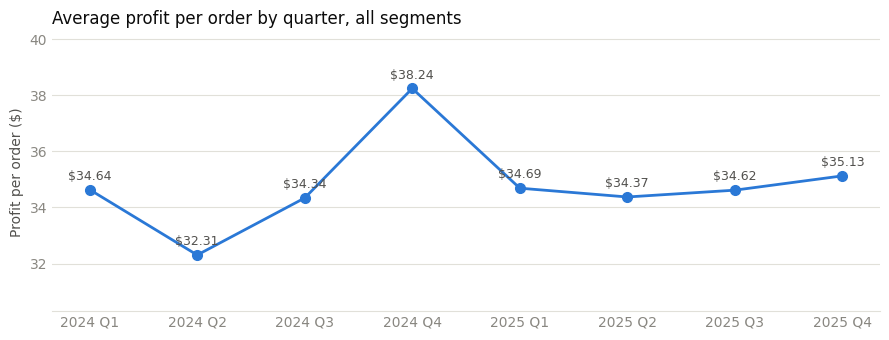

In [ ]:
q = pivot.loc["All segments", quarters]
ax = q.plot(figsize=(9, 3.5), marker="o", linewidth=2, color="#2a78d6")
for x, v in enumerate(q):
    ax.annotate(f"${v:.2f}", (x, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks(range(len(q)), q.index)
ax.set(title="Average profit per order by quarter, all segments", ylabel="Profit per order ($)")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.2)
plt.show()

## 5. What drives the differences

Profit per order = order value × margin. This splits each segment's profit into those two parts.

In [ ]:
drivers = (orders.groupby("customer_segment")
                 .agg(orders=("order_id", "size"),
                      units_per_order=("units", "mean"),
                      avg_order_value=("revenue", "mean"),
                      profit_per_order=("profit", "mean"))
                 .sort_values("profit_per_order", ascending=False)
                 .rename_axis("Segment"))
drivers["margin"] = drivers.profit_per_order / drivers.avg_order_value

(drivers.style
        .format({"orders": "{:,}", "units_per_order": "{:.2f}", "avg_order_value": "${:.2f}",
                 "profit_per_order": "${:.2f}", "margin": "{:.1%}"})
        .highlight_min(subset="margin", color="#fde2e1")
        .highlight_max(subset="margin", color="#dcebfb"))

,orders,units_per_order,avg_order_value,profit_per_order,margin
Segment,,,,,
Tech Enthusiast,"29,175",1.96,$180.59,$85.88,47.6%
Young Parent,"27,133",1.98,$79.53,$31.94,40.2%
Beauty Lover,"27,818",1.77,$62.81,$30.21,48.1%
Home Organizer,"27,936",1.55,$59.89,$26.52,44.3%
Fashion Shopper,"27,951",1.92,$72.75,$25.85,35.5%
Cozy Homemaker,"27,985",1.53,$58.74,$25.57,43.5%
Fitness Buff,"27,123",1.54,$58.66,$25.49,43.5%
Bargain Hunter,"28,159",1.68,$58.00,$24.39,42.0%


## 6. Seasonality checks

In [ ]:
seg = pivot.drop(index="All segments")[quarters]
year_avg = orders.groupby(orders.order_time.dt.year).profit.mean()

checks = {}
for year in [2024, 2025]:
    q = seg.filter(like=str(year))
    checks[f"Best quarter {year}"] = q.idxmax(axis=1).str[4:]
    checks[f"Worst quarter {year}"] = q.idxmin(axis=1).str[4:]
    q4 = pivot.loc["All segments", f"{year}Q4"]
    print(f"{year}: ${year_avg[year]:.2f} per order on average; Q4 ${q4:.2f} ({q4 / year_avg[year] - 1:+.1%} vs the year)")

display(pd.DataFrame(checks))

,Best quarter 2024,Worst quarter 2024,Best quarter 2025,Worst quarter 2025
Segment,,,,
Tech Enthusiast,Q4,Q2,Q4,Q2
Young Parent,Q4,Q3,Q3,Q2
Beauty Lover,Q4,Q2,Q1,Q3
Home Organizer,Q4,Q2,Q2,Q4
Fashion Shopper,Q4,Q2,Q2,Q1
Cozy Homemaker,Q4,Q2,Q1,Q3
Fitness Buff,Q4,Q2,Q2,Q1
Bargain Hunter,Q4,Q2,Q4,Q2


Average profit per order: 2024 $34.89, 2025 $34.70
Q4 2024: $38.24 (+9.6% vs the 2024 average)
Q4 2025: $35.13 (+1.2% vs the 2025 average)


## 7. Conclusion

**Tech Enthusiasts lead every quarter by a wide margin; the other seven segments sit close together at $24–32 per order.**

**What drives the differences**
- **Tech Enthusiasts profit from bigger baskets, not better margins.** Their average order ($180.59) is 2.3–3.1× the other segments' ($58–80), while their margin (47.6%) is close to Beauty Lovers' (48.1%).
- **Fashion Shoppers have the lowest margin (35.5%).** Their baskets are the third largest ($72.75), yet they rank fifth on profit. That points to pricing or vendor mix in clothing rather than customer behaviour.
- **Beauty Lovers have the highest margin (48.1%) on small baskets** ($62.81). Larger baskets would raise their profit the most.

**Seasonality**
- **2024 had a clear Q4 peak.** Q4 was the best quarter for all eight segments, at $38.24 per order, 9.6% above the 2024 average. Q2 was the weakest quarter for seven of eight segments (Young Parents' low was Q3).
- **2025 was much flatter.** Q4 was only 1.2% above the 2025 average, and each segment's best and worst quarters varied.
- **Year over year the average is flat:** $34.89 in 2024 against $34.70 in 2025.

**Limits**
- **5% of delivered orders are left out.** 11,711 orders ($405k profit) come from buyers who aren't in the customer table, so they have no segment.
- **Profit is an estimate.** It's quantity × today's catalog price × margin. Discounts and past price changes aren't captured, so quarterly changes reflect basket size and mix, not pricing.
- **If "segment" should mean the VIP / Frequent / Dormant grouping** (`customer_group`), swap that column for `customer_segment` and re-run.